# 02 · The stop graph

Week 2 turns the GTFS tables into a directed, weighted graph (`transitshock.build_graph`).

- **Nodes:** stops served on Wed 2026-11-04. Rail platforms are merged into their station.
- **Transit edges:** consecutive stops on any trip. The weight is the median scheduled travel time in seconds, with a 15 s floor.
- **Walk edges:** pairs of stops within 200 m. The weight is walking time at 1.3 m/s. A walk edge is added only where no transit edge already exists.

Build the graphs first from the repo root:

```
python -m transitshock.build_graph lbt --date 20261104
python -m transitshock.build_graph lbt metro_bus metro_rail --date 20261104
```

In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from transitshock.build_graph import graph_summary, load_graph

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

G = load_graph(PROCESSED / "lbt_20261104.gpickle")
edges = pd.DataFrame([{"u": u, "v": v, **d} for u, v, d in G.edges(data=True)])
nodes = pd.DataFrame.from_dict(dict(G.nodes(data=True)), orient="index")
graph_summary(G)

nodes                             1853
transit edges                     1990
walk edges                        3890
weakly connected components          1
largest weak component share       1.0
strongly connected components        1
largest strong component share     1.0
mean out-degree                   3.17
dtype: object

## 1. What do walking transfers do to connectivity?

A directed graph is *strongly connected* when every stop can reach every other stop. Comparing the graph with and without walk edges shows how much the network relies on walking between stops.

In [2]:
def transit_only(G):
    T = nx.DiGraph()
    T.add_nodes_from(G.nodes(data=True))
    T.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if d["kind"] == "transit")
    return T

pd.DataFrame({"transit only": graph_summary(transit_only(G)), "transit + walk": graph_summary(G)})

,transit only,transit + walk
nodes,1853,1853
transit edges,1990,1990
walk edges,0,3890
weakly connected components,1,1
largest weak component share,1.0,1.0
strongly connected components,153,1
largest strong component share,0.918,1.0
mean out-degree,1.07,3.17


In [3]:
# What are the small strongly connected pieces in the transit-only graph?
T = transit_only(G)
small = [c for c in nx.strongly_connected_components(T) if len(c) < 0.5 * len(T)]
sizes = pd.Series([len(c) for c in small]).value_counts().sort_index()
print(f"{len(small)} small components covering {sum(map(len, small))} stops")
print("component size -> count:", sizes.to_dict())
example = max(small, key=len)
nodes.loc[list(example), ["name", "routes", "trips_per_day"]].head(10)

152 small components covering 152 stops
component size -> count: {1: 152}


,name,routes,trips_per_day
lbt:2290,Lakewood & Rosecrans NE,21,3


## 2. Edge weights

,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
transit,1990.0,71.9,161.7,15.0,43.0,60.0,78.0,5160.0
walk,3890.0,72.8,43.1,7.9,37.1,58.7,114.8,153.8


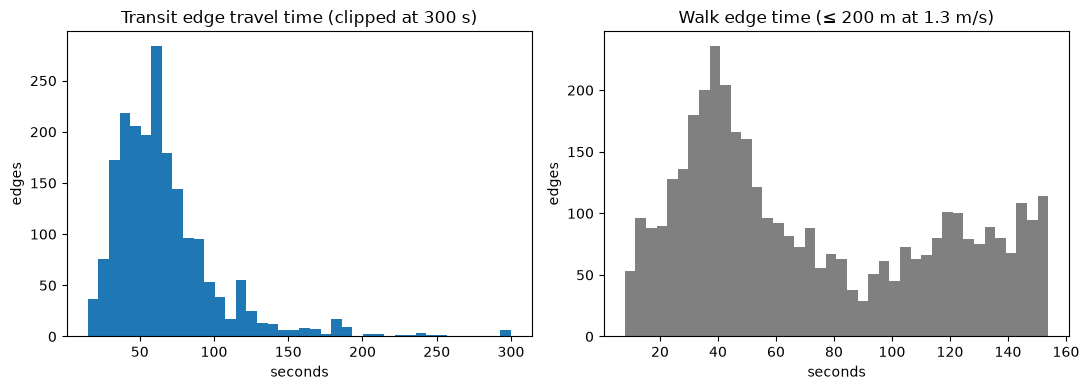

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
transit_w = edges.loc[edges["kind"] == "transit", "weight"]
walk_w = edges.loc[edges["kind"] == "walk", "weight"]
axes[0].hist(transit_w.clip(upper=300), bins=40)
axes[0].set(title="Transit edge travel time (clipped at 300 s)", xlabel="seconds", ylabel="edges")
axes[1].hist(walk_w, bins=40, color="gray")
axes[1].set(title="Walk edge time (≤ 200 m at 1.3 m/s)", xlabel="seconds", ylabel="edges")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_edge_weights.png", dpi=150)
edges.groupby("kind")["weight"].describe().round(1)

In [5]:
# Busiest segments by trips per day
busiest = edges[edges["kind"] == "transit"].nlargest(10, "trips")
busiest.assign(
    from_stop=busiest["u"].map(nodes["name"]),
    to_stop=busiest["v"].map(nodes["name"]),
)[["from_stop", "to_stop", "trips", "weight", "routes"]]

,from_stop,to_stop,trips,weight,routes
1516,7th & Channel SE,W Campus & Library East Side,249.0,107.0,"121,171,175,41,46,91,92,93,94"
2439,W Campus & Library East Side,Beach Dr & W Campus N,249.0,90.0,"121,171,175,41,46,91,92,93,94"
2441,Beach Dr & W Campus N,Beach Dr & Dorms N,249.0,93.0,"121,171,175,41,46,91,92,93,94"
761,Ocean & Atlantic NW,Ocean & Elm NW,181.0,63.0,"121,21,22,61"
1527,Beach Dr & Dorms S,Beach Dr & W Campus S,171.0,77.0,"121,171,91,92,93,94"
1529,Beach Dr & W Campus S,W Campus & Library West Side,171.0,87.0,"121,171,91,92,93,94"
4858,Artesia & Long Beach Blvd NW,Artesia & Harbor NW,170.0,60.0,"141,51,61"
4861,Artesia & Harbor NW,Artesia & Santa Fe NE,170.0,111.0,"141,51,61"
4863,Artesia & Santa Fe NE,Acacia & Artesia NE,170.0,180.0,"141,51,61"
995,Pacific & 7th SW,Pacific & 5th SW,169.0,76.0,"172,173,174,182,91,92,93,94"


## 3. Degree distribution

,in,out,transit out
count,1853.00,1853.00,1853.00
mean,3.17,3.17,1.07
std,1.57,1.50,0.30
min,1.00,1.00,0.00
25%,2.00,2.00,1.00
50%,3.00,3.00,1.00
75%,4.00,4.00,1.00
max,13.00,12.00,4.00


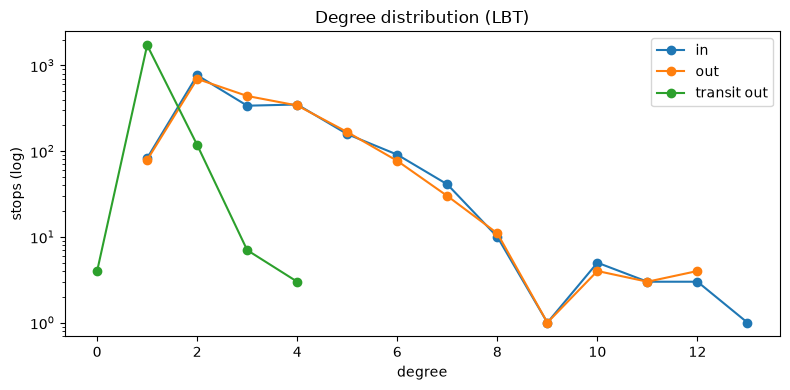

In [6]:
deg = pd.DataFrame({
    "in": dict(G.in_degree()),
    "out": dict(G.out_degree()),
    "transit out": dict(transit_only(G).out_degree()),
})
fig, ax = plt.subplots(figsize=(8, 4))
for col in deg:
    counts = deg[col].value_counts().sort_index()
    ax.plot(counts.index, counts.values, marker="o", label=col)
ax.set(yscale="log", title="Degree distribution (LBT)", xlabel="degree", ylabel="stops (log)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "lbt_degree_distribution.png", dpi=150)
deg.describe().round(2)

## 4. Which stops look most important?

Three different ideas of "important":
- **Degree:** how many direct connections a stop has.
- **Trips per day:** how much service passes through it.
- **Betweenness:** how often it lies on the fastest path between other stops, using travel time as the weight.

Week 3 will test which of these best predicts real disruption.

In [7]:
%%time
betweenness = pd.Series(nx.betweenness_centrality(G, weight="weight"), name="betweenness")

CPU times: user 6.1 s, sys: 128 ms, total: 6.22 s
Wall time: 6.24 s


In [8]:
ranked = nodes[["name", "n_routes", "trips_per_day"]].assign(
    degree=pd.Series(dict(G.degree())),
    betweenness=betweenness,
)
top = {
    "degree": ranked.nlargest(10, "degree"),
    "trips_per_day": ranked.nlargest(10, "trips_per_day"),
    "betweenness": ranked.nlargest(10, "betweenness"),
}
top["betweenness"].round(4)

,name,n_routes,trips_per_day,degree,betweenness
lbt:0255,Cherry & Wardlow SW,3,92,8,0.0935
lbt:1553,Del Amo & Orange SW,1,35,9,0.0911
lbt:0256,Cherry & 33rd SW,3,92,6,0.0763
lbt:0198,Cherry & Spring NE,3,96,7,0.0731
lbt:0199,Cherry & 33rd SE,3,96,5,0.0712
lbt:4126,Wardlow Station Bay 3,3,119,12,0.0707
lbt:1552,Del Amo & Atlantic SE,1,35,8,0.0690
lbt:0200,Cherry & Wardlow NE,2,65,6,0.0653
lbt:0201,Cherry & 36th NE,2,65,6,0.0653
lbt:0202,Cherry & 37th E,2,65,6,0.0651


In [9]:
top["degree"].round(4)

,name,n_routes,trips_per_day,degree,betweenness
lbt:4002,1st & Shelter B N,2,136,24,0.0109
lbt:4003,1st & Shelter C N,4,200,24,0.0082
lbt:4011,1st & Shelter G S,2,265,24,0.0065
lbt:4012,1st & Shelter H S,6,243,23,0.0129
lbt:4068,1st & Long Beach Blvd NE,4,92,23,0.0091
lbt:4008,1st & Shelter F S,3,134,22,0.0003
lbt:4004,1st & Shelter D N,4,115,21,0.0038
lbt:4071,Ocean & Pine SE,1,27,21,0.0004
lbt:2423,Ocean & Long Beach NW,4,137,20,0.0045
lbt:2424,Ocean & Pine NE,4,137,20,0.0046


In [10]:
# Do the three rankings agree? (Spearman rank correlation across all stops)
ranked[["degree", "trips_per_day", "betweenness", "n_routes"]].corr(method="spearman").round(2)

,degree,trips_per_day,betweenness,n_routes
degree,1.00,0.20,0.19,0.20
trips_per_day,0.20,1.00,-0.06,0.76
betweenness,0.19,-0.06,1.00,-0.02
n_routes,0.20,0.76,-0.02,1.00


## 5. Map of the graph

Red lines are transit edges (thicker means more trips per day) and gray lines are walk edges. Circles show the top 15 stops by betweenness. Saved to `figures/lbt_graph_map.html`.

In [11]:
m = folium.Map(location=[nodes["lat"].mean(), nodes["lon"].mean()], zoom_start=12)
max_trips = edges["trips"].max()
for e in edges.itertuples():
    a, b = G.nodes[e.u], G.nodes[e.v]
    if e.kind == "transit":
        folium.PolyLine([(a["lat"], a["lon"]), (b["lat"], b["lon"])],
                        color="#D62028", weight=1 + 5 * e.trips / max_trips, opacity=0.7).add_to(m)
    else:
        folium.PolyLine([(a["lat"], a["lon"]), (b["lat"], b["lon"])],
                        color="#777777", weight=1, opacity=0.5).add_to(m)
for node, row in ranked.nlargest(15, "betweenness").iterrows():
    folium.CircleMarker([nodes.at[node, "lat"], nodes.at[node, "lon"]], radius=7,
                        color="black", fill=True, fill_color="#FDB913", fill_opacity=0.9,
                        popup=f"{row['name']}: betweenness {row['betweenness']:.3f}").add_to(m)
m.save(FIGURES / "lbt_graph_map.html")
# Run `m` in a cell to view the map inline; left out to keep the notebook small.
print("saved", FIGURES / "lbt_graph_map.html")

saved /Users/manuelsoriano/Documents/Personal Projects/transit project/figures/lbt_graph_map.html


## 6. Scaling up: LBT + Metro bus + Metro rail

In [12]:
combined_path = PROCESSED / "lbt+metro_bus+metro_rail_20261104.gpickle"
if combined_path.exists():
    LA = load_graph(combined_path)
    by_feed = pd.Series([f for _, f in LA.nodes(data="feed")]).value_counts()
    cross_feed_walks = sum(
        1 for u, v, k in LA.edges(data="kind") if k == "walk" and LA.nodes[u]["feed"] != LA.nodes[v]["feed"]
    )
    display(pd.DataFrame({"LBT": graph_summary(G), "LBT + Metro": graph_summary(LA)}))
    print("nodes by feed:", by_feed.to_dict())
    print("walk edges linking different agencies:", cross_feed_walks)
else:
    print("Build it first: python -m transitshock.build_graph lbt metro_bus metro_rail --date 20261104")

,LBT,LBT + Metro
nodes,1853,13847
transit edges,1990,15045
walk edges,3890,29821
weakly connected components,1,1
largest weak component share,1.0,1.0
strongly connected components,1,1
largest strong component share,1.0,1.0
mean out-degree,3.17,3.24


nodes by feed: {'metro_bus': 11883, 'lbt': 1853, 'metro_rail': 111}
walk edges linking different agencies: 2132


## Findings

**Graph size (LBT, Wed 2026-11-04):** 1,853 nodes, 1,990 transit edges, and 3,890 walk edges. The median transit edge takes 60 s and the median walk edge 59 s (76 m). The largest edges are route 405's 78–86 minute freeway runs to UCLA.

**Walking is what holds the directed network together.** Transit edges alone form 153 strongly connected components: 91.8% of stops in one large component plus 152 single stops. Those single stops are mostly route ends, where a bus arrives at one stop and leaves from a different one. Adding 200 m walking transfers makes the network fully strongly connected, so every stop can reach every other stop. This means the walking radius is a modeling choice that affects resilience results, and it's worth testing in Week 3 (for example 100, 200, and 400 m).

**The three importance measures disagree a lot** (Spearman correlations):
- Degree vs. betweenness is only 0.19, and trips/day vs. betweenness is −0.06.
- Highest **degree** is the downtown transit mall (1st & Shelter bays A–H, degree 21–24). It's inflated by walk edges between closely packed bays.
- Highest **service** is CSULB and downtown (up to 327 trips/day). Trips/day tracks the number of routes (ρ = 0.76).
- Highest **betweenness** is the Cherry Ave corridor (Wardlow/Spring/33rd), Wardlow Station, and Del Amo & Orange/Atlantic. Del Amo & Orange has 1 route and only 35 trips/day, yet it's the 2nd most "between" stop. It looks like a bridge between parts of the network.

That gap is the core question for Week 3: busy stops and structurally critical stops are different stops. The resilience simulation will show which measure actually predicts damage when a stop is removed.

**Scale:** LBT + Metro bus + Metro rail together build in about 12 s: 13,847 nodes (11,883 Metro bus, 1,853 LBT, 111 rail stations) and 44,866 edges. 2,132 walk edges link stops of different agencies, so the combined graph is also fully strongly connected.

**Limitations to note in the README:**
- Transfers have no time penalty: the model adds no waiting time when switching routes, so it underestimates real travel times. A fixed or headway-based transfer wait could be added to the edge weights.
- Fares are not modeled. LBT charges for transfers, but travel time is the only cost in this graph.
- Weights are scheduled medians, and about 86% of bus times are interpolated.
- One weekday only; frequency is stored as an attribute but not yet used in the weights.